<a href="https://colab.research.google.com/github/Lindaoctaviani7/Lindaoctaviani7-Machine-learning_Ganjil_TI3B_2026_244107020002/blob/main/Tugas2_JS9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


load data

In [3]:
import numpy as np
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Data Saya/semester 5/pembelajaran mesin/spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Pra-pemrosesan Data
# hanya membutuhkan kolom 'v1' (label) dan 'v2' (teks). dan juga akan menghapus kolom kosong lainnya.
data = df[['v1', 'v2']].copy()
data.columns = ['label', 'text']

# Mengubah label menjadi numerik (ham = 0, spam = 1)
data['label_num'] = data['label'].map({'ham': 0, 'spam': 1})

# Membagi data menjadi data latih (train) dan data uji (test)
X_train, X_test, y_train, y_test = train_test_split(
    data['text'],
    data['label_num'],
    test_size=0.2,
    random_state=42
)

print("Tugas 1: Multinomial NB dengan CountVectorizer")
# Menggunakan CountVectorizer dengan mengaktifkan stop_words
count_vectorizer = CountVectorizer(stop_words='english')
X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

# Inisialisasi dan latih model
model_count = MultinomialNB()
model_count.fit(X_train_count, y_train)

# Prediksi dan Evaluasi
y_pred_count = model_count.predict(X_test_count)
acc_count = accuracy_score(y_test, y_pred_count)
print(f"Akurasi CountVectorizer: {acc_count * 100:.2f}%")
print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred_count, target_names=['ham', 'spam']))

print("\n" + "="*50 + "\n")

print("Tugas 2: Multinomial NB dengan TF-IDF")
# Menggunakan TfidfVectorizer dengan mengaktifkan stop_words
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Inisialisasi dan latih model
model_tfidf = MultinomialNB()
model_tfidf.fit(X_train_tfidf, y_train)

# Prediksi dan Evaluasi
y_pred_tfidf = model_tfidf.predict(X_test_tfidf)
acc_tfidf = accuracy_score(y_test, y_pred_tfidf)
print(f"Akurasi TF-IDF: {acc_tfidf * 100:.2f}%")
print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred_tfidf, target_names=['ham', 'spam']))

print("\n" + "="*50 + "\n")

# Perbandingan dan Kesimpulan
print("Kesimpulan")
print(f"1. Akurasi CountVectorizer : {acc_count * 100:.2f}%")
print(f"2. Akurasi TF-IDF          : {acc_tfidf * 100:.2f}%")

if acc_count > acc_tfidf:
    print("\nKesimpulan: Fitur CountVectorizer memberikan akurasi yang lebih baik pada kasus data spam.csv ini.")
    print("Hal ini sering terjadi karena pada klasifikasi spam Naive Bayes, frekuensi kemunculan kata kunci tertentu secara absolut (CountVectorizer) bisa lebih sensitif dalam mendeteksi spam dibanding pembobotan relatif (TF-IDF).")
elif acc_tfidf > acc_count:
    print("\nKesimpulan: Fitur TF-IDF memberikan akurasi yang lebih baik pada kasus data spam.csv ini.")
    print("TF-IDF bekerja lebih baik karena berhasil menekan bobot kata-kata yang sering muncul tetapi kurang informatif, sehingga fokus pada kata kunci yang benar-benar membedakan spam.")
else:
    print("\nKesimpulan: Kedua fitur menghasilkan akurasi yang sama.")

Tugas 1: Multinomial NB dengan CountVectorizer
Akurasi CountVectorizer: 98.39%
Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       965
        spam       0.96      0.92      0.94       150

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



Tugas 2: Multinomial NB dengan TF-IDF
Akurasi TF-IDF: 96.68%
Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       965
        spam       1.00      0.75      0.86       150

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



Kesimpulan
1. Akurasi CountVectorizer : 98.39%
2. Akurasi TF-IDF          : 96.68%

Kesimpulan: Fitur CountVectorizer memberikan akurasi yang lebih baik pada ka

Visualisasi Perbandingan Model (CountVectorizer vs TF-IDF)

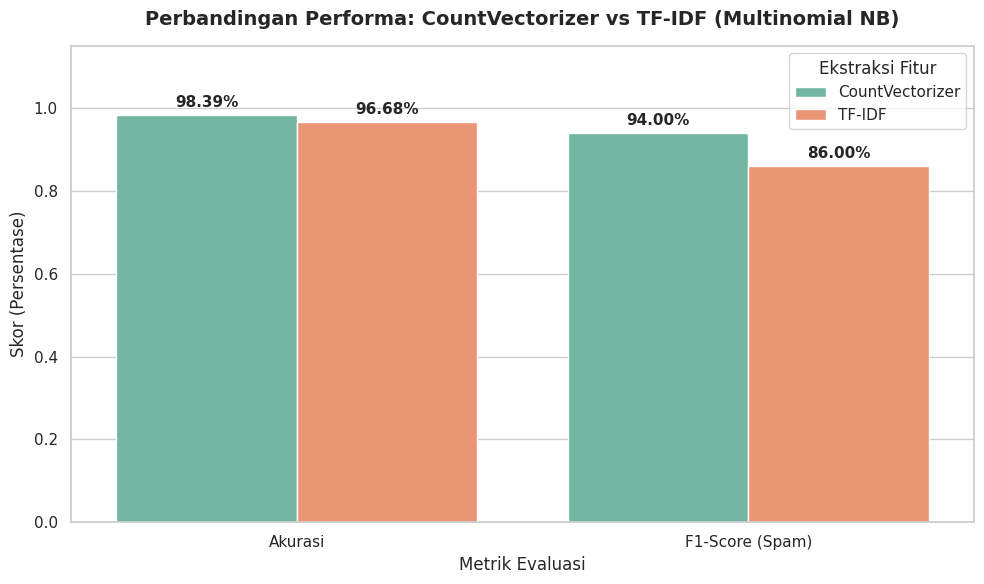

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Data hasil evaluasi
metrics_data = {
    'Metode': ['CountVectorizer', 'CountVectorizer', 'TF-IDF', 'TF-IDF'],
    'Metrik': ['Akurasi', 'F1-Score (Spam)', 'Akurasi', 'F1-Score (Spam)'],
    'Nilai': [0.9839, 0.94, 0.9668, 0.86]
}

df_metrics = pd.DataFrame(metrics_data)

# Membuat plot perbandingan
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(x='Metrik', y='Nilai', hue='Metode', data=df_metrics, palette='Set2')

# Menambahkan nilai di atas batang diagram
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height*100:.2f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=11, fontweight='bold')

plt.title('Perbandingan Performa: CountVectorizer vs TF-IDF (Multinomial NB)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Skor (Persentase)', fontsize=12)
plt.ylim(0, 1.15) # Memberikan ruang untuk label teks di atas chart
plt.xlabel('Metrik Evaluasi', fontsize=12)
plt.legend(title='Ekstraksi Fitur', loc='upper right')
plt.tight_layout()
plt.show()